In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/red-wine-quality-cortez-et-al-2009")

print("Path to dataset files:", path)

100%|██████████████████████████████████████████████████████████████████████████████| 25.6k/25.6k [00:00<00:00, 268kB/s]

Extracting files...
Path to dataset files: C:\Users\chara\.cache\kagglehub\datasets\uciml\red-wine-quality-cortez-et-al-2009\versions\2


In [8]:
import pandas as pd
df=pd.read_csv(r"D:\projects\4NI25CI081_DAV_LAB-main\winequality-red.csv")


In [9]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [6]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import  PCA

In [15]:
from sklearn.preprocessing import MinMaxScaler
x=df.drop("quality",axis=1)
y=df["quality"]

# Initialize MinMaxScaler
normalizer = MinMaxScaler()

x_normalized =normalizer.fit_transform(x)

print("\n Normalized data(first 5 rows):")
print(pd.DataFrame(x_normalized,columns=x.columns).head().round(3))
pca=PCA(n_components=2)
x_pca=pca.fit_transform(x_normalized)

# Apply normalization
normalized_data = scaler.fit_transform(df)

# Convert into DataFrame
normalized_df = pd.DataFrame(normalized_data, columns=df.columns)

print("Normalized Dataset:")
print(normalized_df.round(2))

# Verify minimum and maximum
print("\nMinimum values:")
print(normalized_df.min())

print("\nMaximum values:")
print(normalized_df.max())


 Normalized data(first 5 rows):
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0          0.248             0.397         0.00           0.068      0.107   
1          0.283             0.521         0.00           0.116      0.144   
2          0.283             0.438         0.04           0.096      0.134   
3          0.584             0.110         0.56           0.068      0.105   
4          0.248             0.397         0.00           0.068      0.107   

   free sulfur dioxide  total sulfur dioxide  density     pH  sulphates  \
0                0.141                 0.099    0.568  0.606      0.138   
1                0.338                 0.216    0.494  0.362      0.210   
2                0.197                 0.170    0.509  0.409      0.192   
3                0.225                 0.191    0.582  0.331      0.150   
4                0.141                 0.099    0.568  0.606      0.138   

   alcohol  
0    0.154  
1    0.215  
2    0.2

In [16]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Apply standardization
standardized_data = scaler.fit_transform(df)

# Convert into DataFrame
standardized_df = pd.DataFrame(
    standardized_data,
    columns=df.columns
)

print("Standardized Dataset:")
print(standardized_df.round(2))

# Verify mean and standard deviation
print("\nMean of each feature:")
print(standardized_df.mean().round(2))

print("\nStandard deviation of each feature:")
print(standardized_df.std(ddof=0).round(2))

Standardized Dataset:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0             -0.53              0.96        -1.39           -0.45      -0.24   
1             -0.30              1.97        -1.39            0.04       0.22   
2             -0.30              1.30        -1.19           -0.17       0.10   
3              1.65             -1.38         1.48           -0.45      -0.26   
4             -0.53              0.96        -1.39           -0.45      -0.24   
...             ...               ...          ...             ...        ...   
1594          -1.22              0.40        -0.98           -0.38       0.05   
1595          -1.39              0.12        -0.88           -0.24      -0.54   
1596          -1.16             -0.10        -0.72           -0.17      -0.24   
1597          -1.39              0.65        -0.78           -0.38      -0.26   
1598          -1.33             -1.22         1.02            0.75      -0.43   

     

PCA Transformed Data:
       PC1   PC2
0    -1.78 -1.16
1    -1.00 -2.07
2    -0.92 -1.39
3     2.40  0.21
4    -1.78 -1.16
...    ...   ...
1594 -2.24 -0.60
1595 -2.12  0.37
1596 -1.37  0.52
1597 -2.37 -0.70
1598 -0.29  1.24

[1599 rows x 2 columns]

Explained Variance Ratio:
[0.26009731 0.1868235 ]

Total Variance Retained:
0.4469208117069169


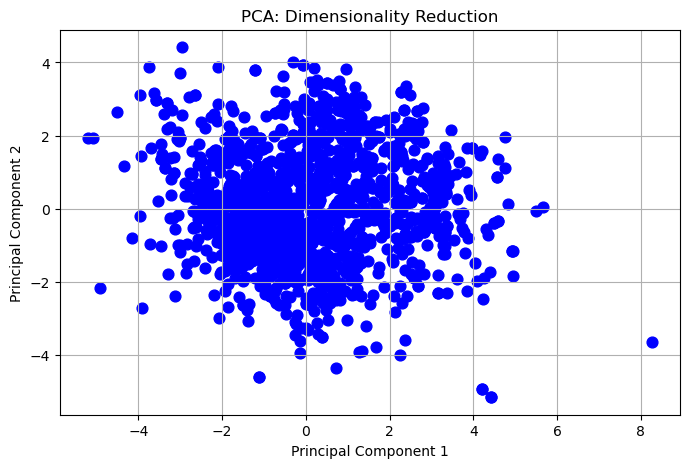

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Standardize the dataset
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

# Apply PCA to reduce 4 features to 2 components
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

# Create a DataFrame
pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

print("PCA Transformed Data:")
print(pca_df.round(2))

# Explained variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Retained:")
print(pca.explained_variance_ratio_.sum())

# Visualize PCA output
plt.figure(figsize=(8, 5))
plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    color='blue',
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Dimensionality Reduction")
plt.grid(True)
plt.show()
